In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.inspection import permutation_importance

In [2]:
# Jeu de données synthétique repris de la séance 7
np.random.seed(42)
n = 2000

age = np.random.uniform(18, 75, n)
revenu = np.clip(np.random.lognormal(np.log(2800), 0.35, n), 1200, 9000)
anciennete = np.clip(np.random.exponential(3, n), 0, 15)
visites = np.random.poisson(5, n)
distance = np.clip(np.random.gamma(2.5, 4, n), 0.2, 40)

ville = np.random.choice(["Tours","Paris","Lyon","Nantes"], n, p=[.30,.30,.20,.20])
statut = np.random.choice(["Nouveau","Régulier","Fidèle"], n, p=[.35,.45,.20])

df = pd.DataFrame({
    "age":age, "revenu":revenu, "anciennete":anciennete,
    "visites":visites, "distance":distance,
    "ville":ville, "statut":statut
})

effet_revenu = np.clip((revenu-2000)/2500, 0, 1.5)
effet_visites = 1.4/(1+np.exp(-(visites-5)))
effet_age = 1.5*np.exp(-((age-40)**2)/(2*12**2))
effet_distance = -0.09*distance
effet_ville = pd.Series(ville).map({"Tours":.5,"Paris":.2,"Lyon":-.1,"Nantes":0}).to_numpy()
effet_statut = pd.Series(statut).map({"Nouveau":-.4,"Régulier":.2,"Fidèle":.8}).to_numpy()

score = -2.4 + 1.2*effet_revenu + effet_visites + effet_age + effet_distance + effet_ville + effet_statut
prob_achat = 1/(1+np.exp(-score))
df["achat"] = np.random.binomial(1, prob_achat)
df.head()

,age,revenu,anciennete,visites,distance,ville,statut,achat
0,39.348787,2059.216379,2.743621,3,19.096238,Nantes,Nouveau,1
1,72.190715,2096.378418,2.162837,6,10.766789,Nantes,Régulier,0
2,59.723655,2586.619485,1.019810,8,12.006206,Nantes,Nouveau,1
3,52.123534,3184.188105,0.019456,4,5.700674,Tours,Régulier,0
4,26.893063,3855.011678,2.056961,4,4.250496,Paris,Nouveau,1


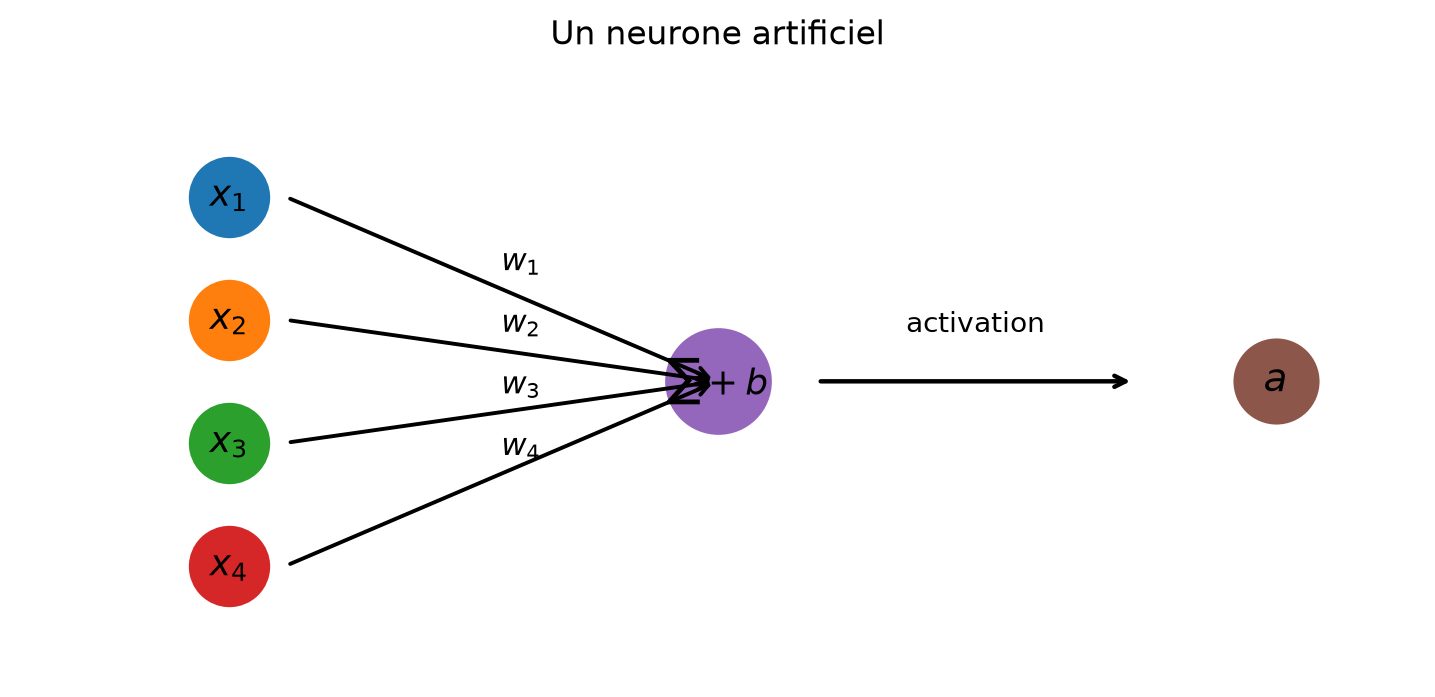

In [3]:
def dessiner_neurone():
    fig, ax = plt.subplots(figsize=(9,4))
    ys = [.78,.58,.38,.18]
    for i,y in enumerate(ys,1):
        ax.scatter(.15,y,s=800)
        ax.text(.15,y,f"$x_{i}$",ha="center",va="center",fontsize=13)
        ax.annotate("",xy=(.50,.48),xytext=(.19,y),
                    arrowprops=dict(arrowstyle="->",lw=1.4))
        ax.text((.19+.50)/2,(y+.48)/2+.03,f"$w_{i}$",fontsize=11)
    ax.scatter(.50,.48,s=1400)
    ax.text(.50,.48,"$\\sum+b$",ha="center",va="center",fontsize=13)
    ax.annotate("",xy=(.80,.48),xytext=(.57,.48),
                arrowprops=dict(arrowstyle="->",lw=1.6))
    ax.text(.685,.56,"activation",ha="center")
    ax.scatter(.90,.48,s=900)
    ax.text(.90,.48,"$a$",ha="center",va="center",fontsize=14)
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
    ax.set_title("Un neurone artificiel")
    plt.show()

dessiner_neurone()

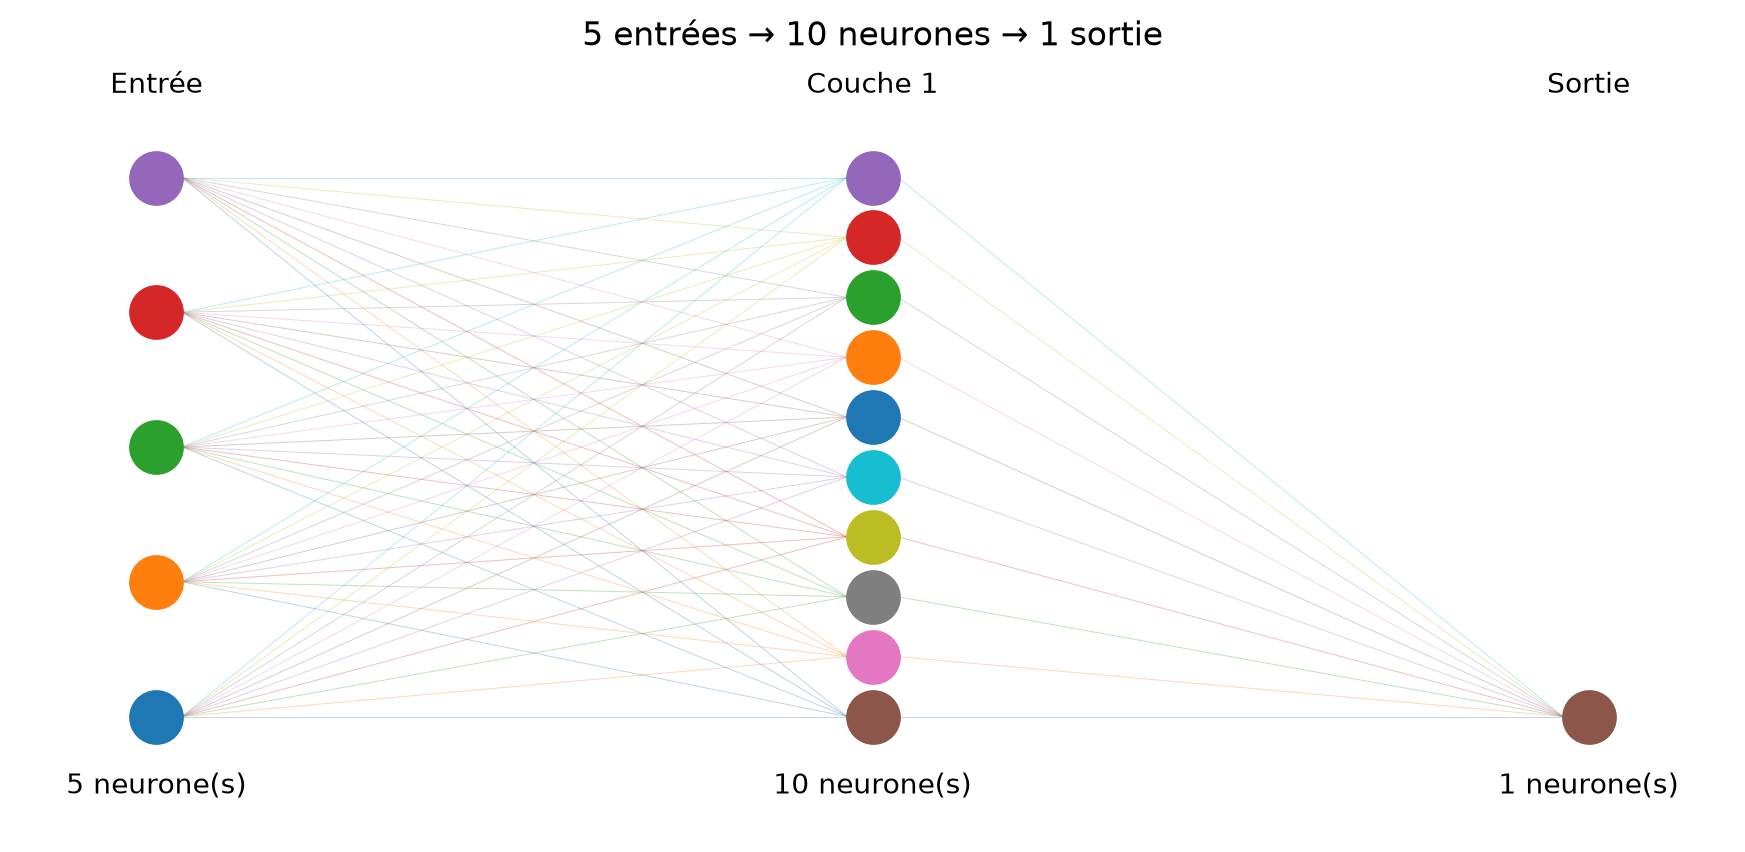

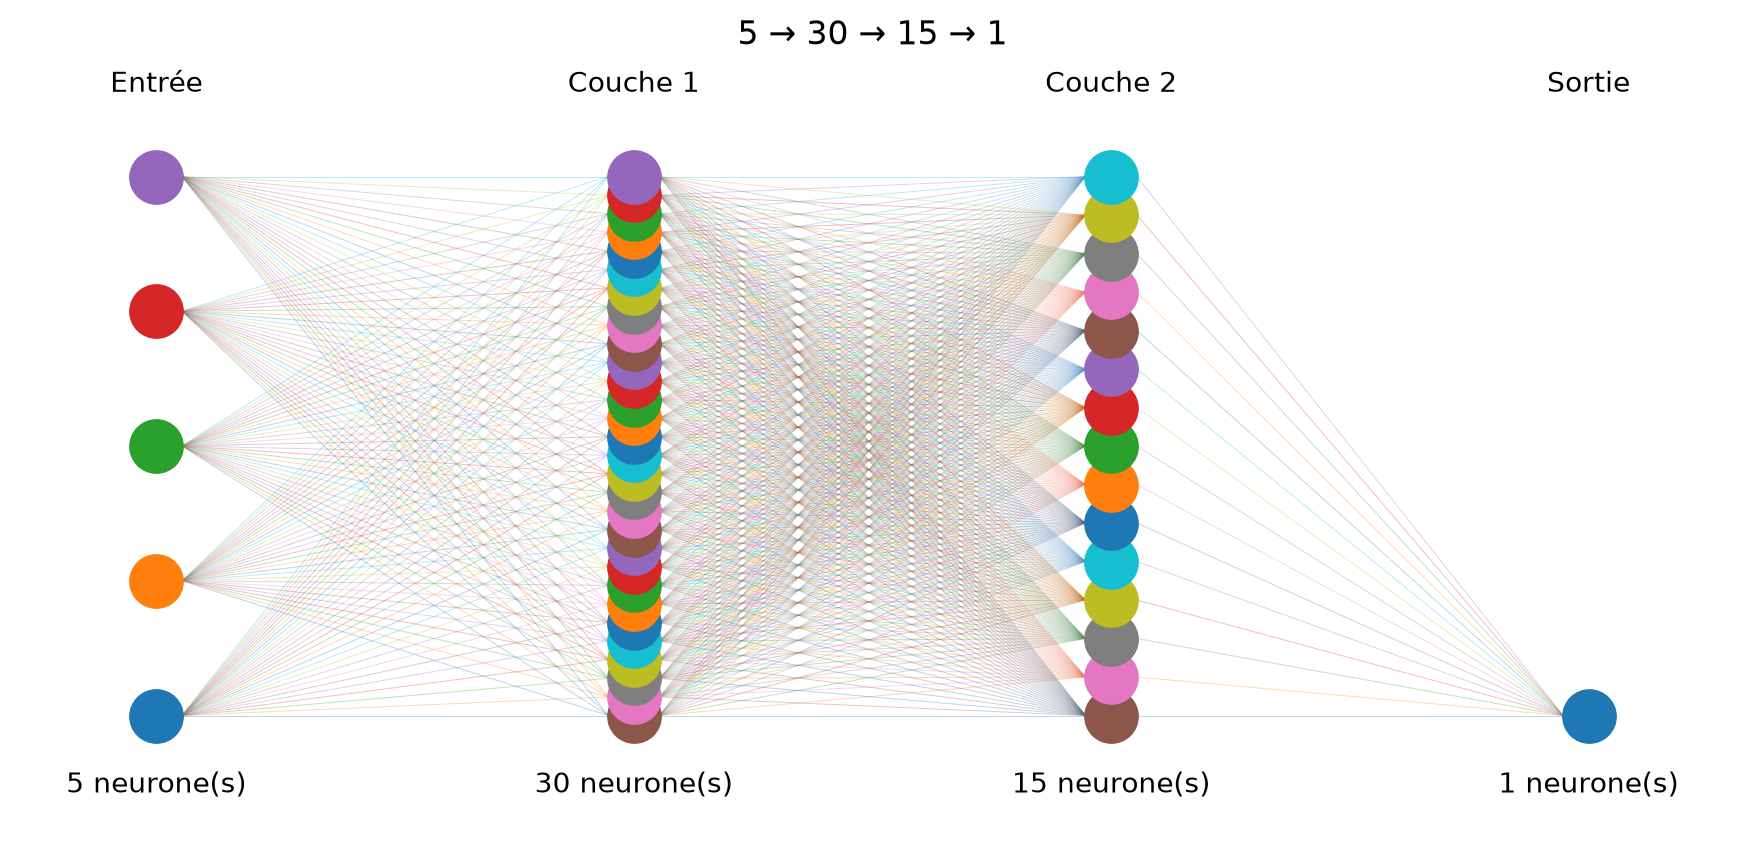

In [4]:
def dessiner_architecture(couches, titre="Architecture du réseau"):
    fig, ax = plt.subplots(figsize=(11,5))
    xs = np.linspace(.08,.92,len(couches))
    for i,(x,n) in enumerate(zip(xs,couches)):
        ys = np.linspace(.15,.85,n)
        for y in ys:
            ax.scatter(x,y,s=350,zorder=3)
        if i < len(couches)-1:
            ys2=np.linspace(.15,.85,couches[i+1])
            for y in ys:
                for y2 in ys2:
                    ax.plot([x+.015,xs[i+1]-.015],[y,y2],lw=.35,alpha=.3)
        label="Entrée" if i==0 else ("Sortie" if i==len(couches)-1 else f"Couche {i}")
        ax.text(x,.96,label,ha="center")
        ax.text(x,.05,f"{n} neurone(s)",ha="center")
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
    ax.set_title(titre)
    plt.show()

dessiner_architecture([5,10,1],"5 entrées → 10 neurones → 1 sortie")
dessiner_architecture([5,30,15,1],"5 → 30 → 15 → 1")

In [5]:
def compter_parametres(couches):
    details=[]
    total=0
    for a,b in zip(couches[:-1],couches[1:]):
        poids=a*b
        biais=b
        details.append([a,b,poids,biais,poids+biais])
        total += poids+biais
    return total, pd.DataFrame(details,columns=["Entrée","Sortie","Poids","Biais","Total"])

for arch in [[5,5,1],[5,10,1],[5,30,1],[5,100,1],[5,30,15,1],[5,50,30,10,1]]:
    total, details=compter_parametres(arch)
    print(arch, "→", total, "paramètres")

[5, 5, 1] → 36 paramètres
[5, 10, 1] → 71 paramètres
[5, 30, 1] → 211 paramètres
[5, 100, 1] → 701 paramètres
[5, 30, 15, 1] → 661 paramètres
[5, 50, 30, 10, 1] → 2151 paramètres


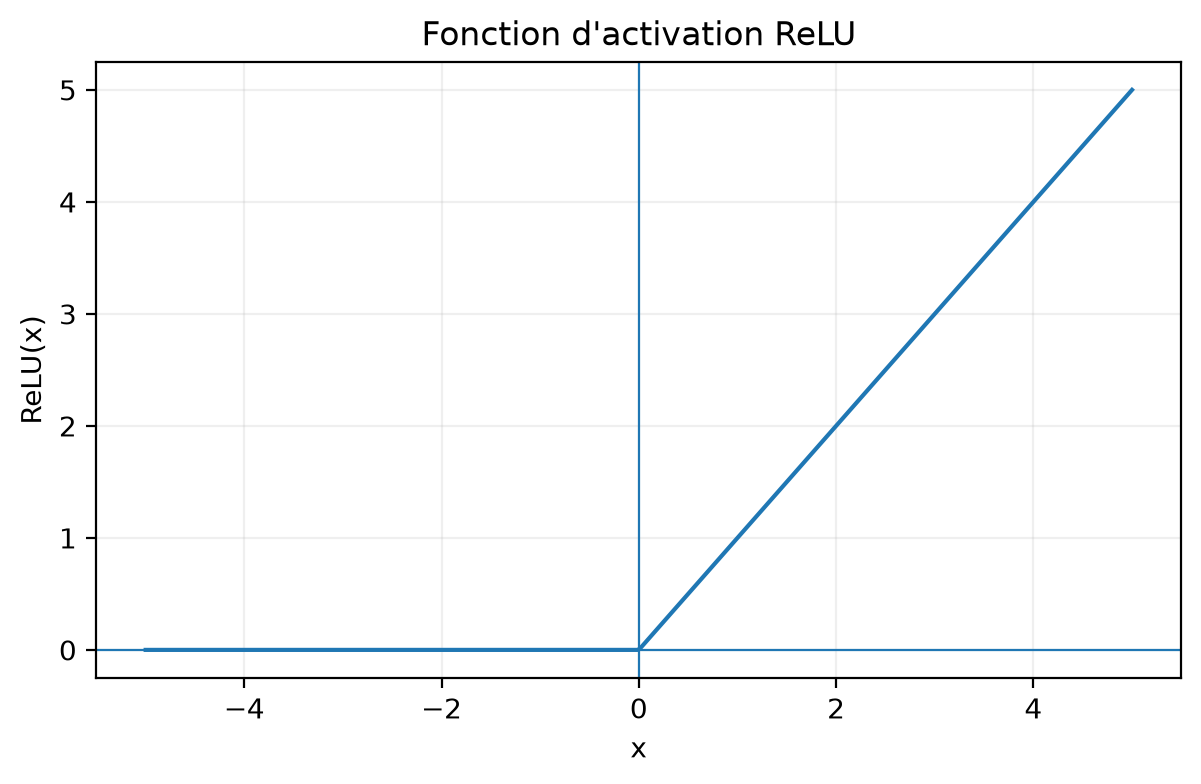

In [6]:
x=np.linspace(-5,5,400)
plt.figure(figsize=(7,4))
plt.plot(x,np.maximum(0,x))
plt.axhline(0,lw=.8); plt.axvline(0,lw=.8)
plt.title("Fonction d'activation ReLU")
plt.xlabel("x"); plt.ylabel("ReLU(x)")
plt.grid(alpha=.2); plt.show()

In [7]:
variables_numeriques=["age","revenu","anciennete","visites","distance"]
variables_categorielles=["ville","statut"]

X=df.drop(columns=["achat"])
y=df["achat"]

prep_num=Pipeline([
    ("imputation",SimpleImputer(strategy="median")),
    ("normalisation",StandardScaler())
])
prep_cat=Pipeline([
    ("imputation",SimpleImputer(strategy="most_frequent")),
    ("encodage",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])
preparation=ColumnTransformer([
    ("numerique",prep_num,variables_numeriques),
    ("categorielle",prep_cat,variables_categorielles)
])

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=.25,stratify=y,random_state=42
)

modele_neurone=Pipeline([
    ("preparation",preparation),
    ("classification",MLPClassifier(
        hidden_layer_sizes=(30,),
        max_iter=2000,
        random_state=42
    ))
])

modele_neurone.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparation', ...), ('classification', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','revenu','anciennete',...,'distance','ville','statut']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerique', ...), ('categorielle', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrou